# Bitacoras onomásticas SEMEFO 1968-1982
# Análisis demográfico

In [1]:
import pandas as pd
from numpy import nan

import matplotlib.pyplot as plt
import seaborn as sns

def summary_top_series(s, n_values=5, sep=', ', **kwargs):
    s = s.value_counts(**kwargs).head(n_values)
    s = s.to_dict()
    s = sep.join([f"{k} ({v})" for k,v in s.items()])
    return s

In [11]:
colors = {'conocido':'#8dd3c7', 'desconocido':'#fb8072',
          'Cadáver conocido':'#8dd3c7', 'Cadáver desconocido':'#fb8072', 'Restos':'#fdb462',
          'Femenino':'#bc80bd', 'Masculino':'#fb8072','S-D':'#999999',
          'Cadáver':'#b3de69', 'Feto':'#fccde5', 'Recién nacido':'#bebada', 'Miembros':'#fdb462', 'Restos óseos':'#ffffb3'}

In [3]:
df = pd.read_pickle('data_clean/SEMEFO_BO_all.pkl')
df['Bitacora_ingresos'] = df['Bitacora_ingresos'].apply(lambda s: s.replace('semefo_df_bo_',''))
df

,ID,Numero_progresivo_transcrito,Nombre_completo_transcrito,Primer_apellido,Segundo_apellido,Nombres_propios,Fecha_transcrito,Fecha_estandar,Fecha_añomes,Fecha_diasemana,...,Procedencia_acta,Diagnostico_transcrito,Diagnostico_estandar,Diagnostico_extendido,Tipo_restos,Conocido_desconocido,Bitacora_ingresos,Pagina_PDF,Foja_transcrito,Observaciones
0,BO_1968_00001,NaN,acosta ortega teresa,acosta,ortega,teresa,1968-01-03,1968-01-03,1968 Enero,Miércoles,...,NaN,S-D,S-D,S-D,Cadáver,conocido,1968,2,1,NaN
1,BO_1968_00002,NaN,avila de cuestas catalina,avila,de cuestas,catalina,1968-01-05,1968-01-05,1968 Enero,Viernes,...,NaN,S-D,S-D,S-D,Cadáver,conocido,1968,2,1,NaN
2,BO_1968_00003,NaN,arzate paredes juan,arzate,paredes,juan,1968-01-07,1968-01-07,1968 Enero,Domingo,...,NaN,S-D,S-D,S-D,Cadáver,conocido,1968,2,1,NaN
3,BO_1968_00004,NaN,alvarez martinez isaac,alvarez,martinez,isaac,1968-01-07,1968-01-07,1968 Enero,Domingo,...,NaN,S-D,S-D,S-D,Cadáver,conocido,1968,2,1,NaN
4,BO_1968_00005,NaN,arellano viuda de campos ma.,arellano,viuda de campos,ma.,1968-01-07,1968-01-07,1968 Enero,Domingo,...,NaN,S-D,S-D,S-D,Cadáver,conocido,1968,2,1,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96839,BO_1982_07489,NaN,placenta,S-D,S-D,S-D,1982-06-05,1982-06-05,1982 Junio,Sábado,...,15A/960,S-D,S-D,S-D,Miembros,desconocido,1982,251,156,NaN
96840,BO_1982_07490,NaN,5 dedos del pie derecho de desconocido,S-D,S-D,S-D,1982-06-05,1982-06-05,1982 Junio,Sábado,...,32A/950,S-D,S-D,S-D,Miembros,desconocido,1982,251,156,NaN
96841,BO_1982_07491,NaN,dedo de desconocido,S-D,S-D,S-D,1982-11-19,1982-11-19,1982 Noviembre,Viernes,...,32A/2005,S-D,S-D,S-D,Miembros,desconocido,1982,251,156,NaN
96842,BO_1982_07492,NaN,4 dedos de desconocido,S-D,S-D,S-D,1982-11-28,1982-11-28,1982 Noviembre,Domingo,...,27A/959,S-D,S-D,S-D,Miembros,desconocido,1982,251,156,NaN


## Missing

In [4]:
pd.DataFrame( df['Bitacora_ingresos'].value_counts().sort_index())

,count
Bitacora_ingresos,
1968,4719
1969,5052
1970,5303
1971,5524
1972,5768
1973,6471
1974,5731
1975,6861
1976,6907


In [5]:
col_trans = [col for col in df.columns if 'transcrito' in col]
col_trans

data = df[col_trans]
data['Año'] = df['Bitacora_ingresos'].replace({'semefo_df_':''}, regex=True)
data = data.replace({'S-D':nan, 's-d':nan})

/tmp/ipykernel_14110/2440187126.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['Año'] = df['Bitacora_ingresos'].replace({'semefo_df_':''}, regex=True)


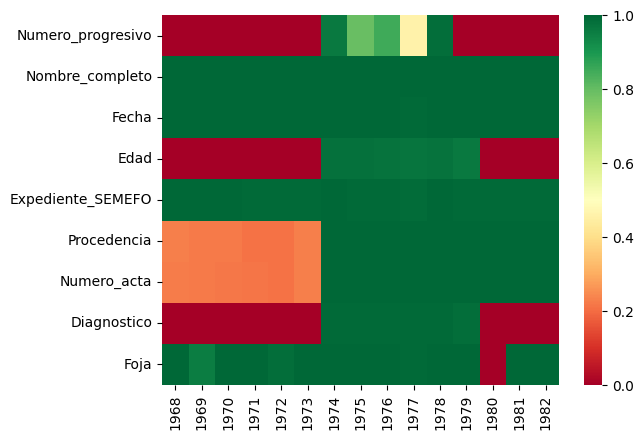

In [6]:
data_miss = data.groupby('Año').agg({col:lambda s: s.notna().sum() / len(s) for col in col_trans })
data_miss.index = [i.replace('semefo_df_bo_','') for i in data_miss.index]
data_miss.columns = [i.replace('_transcrito','') for i in data_miss.columns]
#display( data_miss )
sns.heatmap(data_miss.transpose(), cmap='RdYlGn')
plt.show()

## Tipo de restos

,Frecuencia,Porcentaje
Tipo_restos,,
Cadáver,91254,94.227830
Feto,2844,2.936682
Miembros,2065,2.132295
Recién nacido,633,0.653629
Restos óseos,48,0.049564


<Axes: >

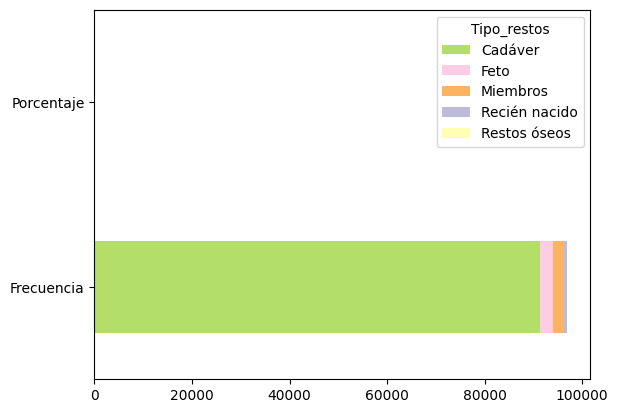

In [12]:
data = df['Tipo_restos'].value_counts()
data = pd.DataFrame(data)
data['mean'] = df['Tipo_restos'].value_counts(normalize=True)*100
data.columns = ['Frecuencia','Porcentaje']
display(data)
data.transpose().plot.barh(stacked=True, color=colors)

In [8]:
data = pd.pivot_table(df, index='Tipo_restos', columns=['Conocido_desconocido','Sexo'], aggfunc="size")
data

Conocido_desconocido conocido                desconocido                
Sexo                 Femenino Masculino  S-D    Femenino Masculino   S-D
Tipo_restos                                                             
Cadáver                 17923     58337  496        1580     12845    73
Recién nacido               8        23    0         243       356     3
Feto                        6         9   16         456       653  1704
Miembros                  361      1405   29          23       106   141
Restos óseos                0         0    0           1         7    40

In [29]:
df[['Tipo_restos_ext','Sexo']].value_counts(normalize=True) \
  .reset_index().sort_values(by='Tipo_restos_ext')

,Tipo_restos_ext,Sexo,proportion
0,Cadáver conocido,Masculino,0.602381
1,Cadáver conocido,Femenino,0.185071
7,Cadáver conocido,S-D,0.005122
2,Cadáver desconocido,Masculino,0.132636
4,Cadáver desconocido,Femenino,0.016315
13,Cadáver desconocido,S-D,0.000754
10,Recién nacido,Masculino,0.003914
11,Recién nacido,Femenino,0.002592
14,Recién nacido,S-D,0.000031
3,Feto,S-D,0.017761


In [9]:
def join_restos(row):
    if row[0] in ['Miembros','Restos óseos']:
        return 'Restos'
    elif row[0]!='Cadáver':
        return row[0]
    else: return row[0]+' '+row[1]

cat_type = ['Cadáver conocido', 'Cadáver desconocido', 'Recién nacido', 'Feto', 'Restos']
cat_type = pd.CategoricalDtype(categories=cat_type, ordered=True)

df['Tipo_restos_ext'] = df[['Tipo_restos','Conocido_desconocido']].apply(join_restos, axis=1).astype(cat_type)
df['Tipo_restos_ext'].value_counts(dropna=False)

Tipo_restos_ext
Cadáver conocido       76756
Cadáver desconocido    14498
Feto                    2844
Restos                  2113
Recién nacido            633
Name: count, dtype: int64

,Frecuencia,Porcentaje
Tipo_restos_ext,,
Cadáver conocido,76756,79.257362
Cadáver desconocido,14498,14.970468
Feto,2844,2.936682
Restos,2113,2.181859
Recién nacido,633,0.653629


<Axes: >

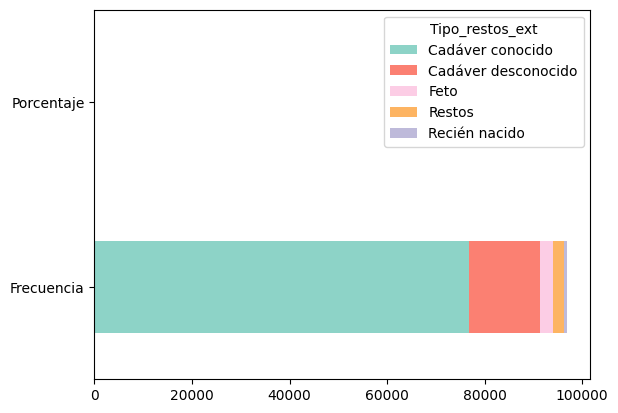

In [13]:
data = df['Tipo_restos_ext'].value_counts()
data = pd.DataFrame(data)
data['mean'] = df['Tipo_restos_ext'].value_counts(normalize=True)*100
data.columns = ['Frecuencia','Porcentaje']
display(data)
data.transpose().plot.barh(stacked=True, color=colors)

In [14]:
data = pd.pivot_table(df, index='Tipo_restos', columns='Conocido_desconocido', aggfunc="size")
data.divide(data.sum(axis=1), axis=0)

Conocido_desconocido,conocido,desconocido
Tipo_restos,,
Cadáver,0.841125,0.158875
Recién nacido,0.048973,0.951027
Feto,0.010900,0.989100
Miembros,0.869249,0.130751
Restos óseos,0.000000,1.000000


In [15]:
data = pd.pivot_table(df, index='Tipo_restos', columns='Sexo', aggfunc="size")
data.divide(data.sum(axis=1), axis=0)

Sexo,Femenino,Masculino,S-D
Tipo_restos,,,
Cadáver,0.213722,0.780043,0.006235
Recién nacido,0.396524,0.598736,0.004739
Feto,0.162447,0.232771,0.604782
Miembros,0.185956,0.731719,0.082324
Restos óseos,0.020833,0.145833,0.833333


In [16]:
data = pd.pivot_table(df, index='Tipo_restos', columns='Bitacora_ingresos', aggfunc="size")
data / data.sum() * 100
#data.transpose().plot.barh(stacked=True, color=colors)

Bitacora_ingresos,1968,1969,1970,1971,1972,1973,1974,1975,1976,1977,1978,1979,1980,1981,1982
Tipo_restos,,,,,,,,,,,,,,,
Cadáver,93.134139,93.982581,93.286819,93.428675,93.463939,92.443208,92.392253,93.659816,94.614160,94.097125,94.719888,94.384131,95.970600,95.713724,96.249833
Recién nacido,0.720492,0.692795,0.999434,0.814627,0.953537,1.282646,0.907346,0.553855,0.115825,0.655875,0.616246,0.442300,0.380627,0.393236,0.627252
Feto,4.852723,3.661916,4.016594,4.091238,3.432732,4.265183,4.309894,3.293980,3.214131,2.525816,2.408964,1.997051,1.653760,1.415651,1.147738
Miembros,1.250265,1.583531,1.602866,1.611151,2.011096,1.746253,2.390508,2.419472,2.041407,2.693274,2.240896,3.176518,1.995012,2.477389,1.975177
Restos óseos,0.042382,0.079177,0.094286,0.054308,0.138696,0.262711,0.000000,0.072876,0.014478,0.027910,0.014006,0.000000,0.000000,0.000000,0.000000


## Edad y sexo

Sexo,Femenino,Masculino,S-D
Edad_rango,,,
"(-1.0, 0.0]",760,1054,5
"(0.0, 4.0]",787,1172,0
"(4.0, 9.0]",464,928,1
"(9.0, 14.0]",320,902,0
"(14.0, 19.0]",607,1806,1
"(19.0, 24.0]",628,3134,0
"(24.0, 29.0]",589,3192,0
"(29.0, 34.0]",451,2557,0
"(34.0, 39.0]",477,2718,1


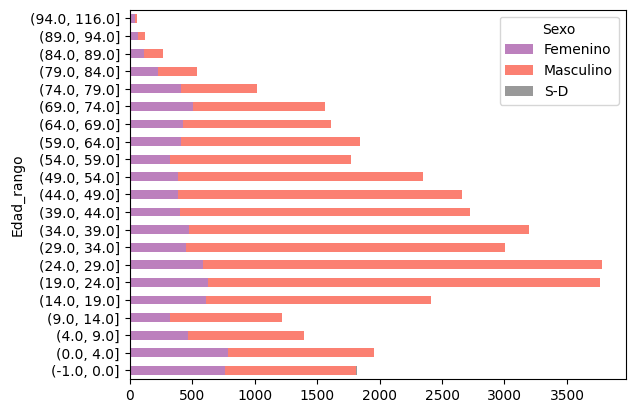

In [31]:
data = df[df['Tipo_restos'].isin(['Cadáver','Recién nacido'])]
data = pd.pivot_table(data, index='Edad_rango', columns='Sexo', aggfunc="size")
data.plot.barh(stacked=True, color=colors)
#plt.savefig('Sexo_EdadRango.svg')
data

<Axes: xlabel='Bitacora_ingresos'>

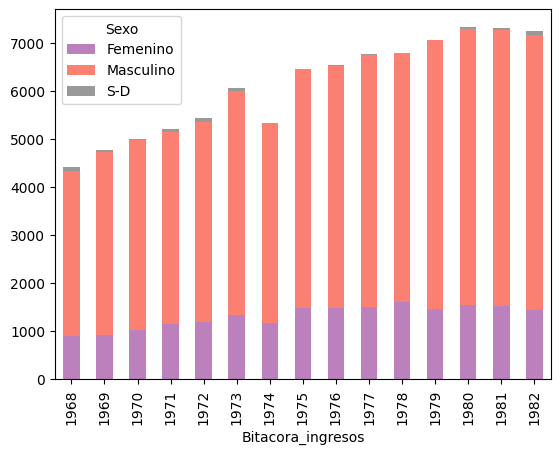

In [19]:
data = df[df['Tipo_restos'].isin(['Cadáver','Recién nacido'])]
data = pd.pivot_table(data, index='Sexo', columns='Bitacora_ingresos', aggfunc="size")
data.transpose().plot.bar(stacked=True, color=colors)

## Procedencia y diagnóstico

## Fecha

In [ ]:
data = pd.pivot_table(df, index='Bitacora_ingresos', columns='Sexo', aggfunc="size")
data.plot.bar(stacked=True, width=1.0, color=colors)

In [ ]:
data = pd.pivot_table(df, index='Bitacora_ingresos', columns='Conocido_desconocido', aggfunc="size")
data.plot.bar(stacked=True, width=1.0, color=colors)

In [ ]:
df.columns